# CS 640 - 2026 Fall - Homework 7

In this homework, you will train a small neural network implementing a policy controlling a cat that wants to move towards a fish.

## Instructions

1. Follow the instructions below to construct and optimize the policy.
2. Run all the cells before submitting.
3. Submit your notebook in Gradescope.


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import torch

## Cat State

The cats have four discrete actions, but their state is real-valued.
Both x and y coordinates have real-valued positions and velocities.
Additionally, the velocity is capped at one and the position updates are noisy.
The cat receives a reward when its distance from the fish is 5 or less.

Read the `act` method in the `CatState` class below for details.

In [4]:
# DO NOT CHANGE

CAT_ACTIONS = {"up": (0, 1), "down" : (0, -1), "left" : (-1, 0), "right": (1, 0)}

class CatState:
    def __init__(self, x, y, vx, vy):
        self.x = x
        self.y = y
        self.vx = vx
        self.vy = vy

    def __repr__(self):
        d = self.distance_to_fish()
        return f"CatState(x={self.x:+.2f}, y={self.y:+.2f}, vx={self.vx:+.2f}, vy={self.vy:+.2f}, distance to fish={d:.2f})"

    def act(self, action):
        dvx, dvy = CAT_ACTIONS[action]

        new_vx = self.vx + dvx
        new_vy = self.vy + dvy
        v = np.sqrt(new_vx**2 + new_vy**2)

        if v > 1:
            new_vx /= v
            new_vy /= v

        new_x = self.x + self.vx + np.random.normal(0, 0.1)
        new_y = self.y + self.vy + np.random.normal(0, 0.1)

        new_state = CatState(new_x, new_y, new_vx, new_vy)

        reward = 1 if self.distance_to_fish() <= 5 else 0

        return (reward, new_state)

    def distance_to_fish(self):
        return np.sqrt((self.x-8)**2 + (self.y - 0)**2)

c0 = CatState(0, 0, 0, 0)
c0

CatState(x=+0.00, y=+0.00, vx=+0.00, vy=+0.00, distance to fish=8.00)

### Uniform Random Cat Walks

Implement a function that uses the CatState class to simulate a uniform random policy (i.e. up/down/left/right with equal probability) for 100 steps and print the resulting actions and rewards.
Run the function twice showing the varying behavior.

In [ ]:
def random_walk(c : CatState):
    for _ in range(100):
        action = np.random.choice(["up", "down", "left", "right"])
        reward, c = c.act(action)
        print(reward, c)

random_walk(CatState(0,0,0,0))


0 CatState(x=+0.10, y=-0.04, vx=+0.00, vy=-1.00, distance to fish=7.90)
0 CatState(x=-0.08, y=-1.22, vx=+0.00, vy=+0.00, distance to fish=8.17)
0 CatState(x=-0.10, y=-1.13, vx=+0.00, vy=+1.00, distance to fish=8.18)
0 CatState(x=-0.07, y=-0.06, vx=-0.71, vy=+0.71, distance to fish=8.07)
0 CatState(x=-1.00, y=+0.82, vx=+0.29, vy=+0.71, distance to fish=9.03)
0 CatState(x=-0.66, y=+1.51, vx=-0.71, vy=+0.71, distance to fish=8.79)
0 CatState(x=-1.46, y=+2.04, vx=+0.29, vy=+0.71, distance to fish=9.68)
0 CatState(x=-1.05, y=+2.88, vx=+0.29, vy=-0.29, distance to fish=9.50)
0 CatState(x=-0.82, y=+2.50, vx=-0.71, vy=-0.29, distance to fish=9.17)
0 CatState(x=-1.53, y=+2.09, vx=-0.71, vy=+0.71, distance to fish=9.76)
0 CatState(x=-2.17, y=+2.91, vx=-0.92, vy=+0.38, distance to fish=10.58)
0 CatState(x=-2.99, y=+3.36, vx=-0.56, vy=+0.83, distance to fish=11.49)
0 CatState(x=-3.41, y=+3.94, vx=-0.56, vy=-0.17, distance to fish=12.07)
0 CatState(x=-3.90, y=+3.78, vx=+0.44, vy=-0.17, distance to 

## Optimize a Policy

You will optimize the following policy to maximize the cat's rewards.

In [5]:
# DO NOT CHANGE

CAT_ACTION_ORDER = ["up", "down", "left", "right"]

class ShallowPolicy(torch.nn.Module):
    def __init__(self, input_size=4, hidden_size=128, output_size=4):
        super().__init__()

        self.fc_1 = torch.nn.Linear(input_size, hidden_size)
        self.fc_2 = torch.nn.Linear(hidden_size, output_size)

        self.relu = torch.nn.ReLU()
        self.softmax = torch.nn.Softmax(dim=0)

    def forward(self, x):
        logits = self.fc_2(self.relu(self.fc_1(x)))
        # print("LOGITS", logits)
        return self.softmax(logits)

pi = ShallowPolicy()

### Construct input tensors.


In [6]:
def compute_state_tensor(s):
    return torch.tensor([s.x, s.y, s.vx, s.vy], dtype=torch.float32)

### Test your tensor conversion.

In [11]:
# DO NOT CHANGE

compute_state_tensor(c0)

tensor([0., 0., 0., 0.])

In [12]:
# DO NOT CHANGE

compute_state_tensor(CatState(1, 2, 3, 4))

tensor([1., 2., 3., 4.])

### Write a function using a policy to pick an action for the state.

In [7]:
def pick_action(policy, s):
    state = compute_state_tensor(s)
    p = policy(state)
    action = torch.distributions.Categorical(p).sample()
    return CAT_ACTION_ORDER[action]

pick_action(pi, c0)

'down'

### Test picking actions

Use the policy `pi` to pick 10 actions starting from the initial state `c0`.

Log each action in the following format.
```
ACTION down STATE CatState(x=+0.09, y=+0.07, vx=+0.00, vy=-1.00, distance to fish=7.91)
```

In [21]:
c = c0
for _ in range(10):
    action = pick_action(pi, c)
    _, c = c.act(action)
    print(f"ACTION {action} STATE {c}")

ACTION down STATE CatState(x=+0.03, y=+0.16, vx=+0.00, vy=-1.00, distance to fish=7.98)
ACTION left STATE CatState(x=+0.10, y=-0.84, vx=-0.71, vy=-0.71, distance to fish=7.94)
ACTION up STATE CatState(x=-0.53, y=-1.55, vx=-0.71, vy=+0.29, distance to fish=8.67)
ACTION left STATE CatState(x=-1.17, y=-1.32, vx=-0.99, vy=+0.17, distance to fish=9.26)
ACTION down STATE CatState(x=-2.07, y=-1.20, vx=-0.76, vy=-0.64, distance to fish=10.15)
ACTION left STATE CatState(x=-2.92, y=-1.82, vx=-0.94, vy=-0.34, distance to fish=11.07)
ACTION up STATE CatState(x=-3.83, y=-2.17, vx=-0.82, vy=+0.57, distance to fish=12.03)
ACTION right STATE CatState(x=-4.72, y=-1.51, vx=+0.18, vy=+0.57, distance to fish=12.81)
ACTION up STATE CatState(x=-4.51, y=-1.14, vx=+0.11, vy=+0.99, distance to fish=12.56)
ACTION right STATE CatState(x=-4.29, y=-0.09, vx=+0.75, vy=+0.67, distance to fish=12.29)


## Implement the REINFORCE algorithm as covered in class.

Train your policy using episodes of 100 actions and the REINFORCE algorithm.
The goal should be maximizing the total reward in each episode.
Save the total rewards for each episode to be plotted later.
Use $\gamma$ = 1.0 and $\alpha=0.001$.

During the REINFORCEMENT algorithm, if the selected action probability is zero, skip the parameter update.
This may happen due to parameter changes since the action was chosen.

You will probably need 1,000-10,000 episodes to train the the policy.
An average total reward of 50 in autograder testing will receive full credit.
(Close to 90 is possible.)

In [8]:
def reinforce(policy, episodes):
    states = [None] * 100
    actions = [None] * 100
    rewards = np.zeros(100)
    pi = policy
    optimizer = torch.optim.Adam(pi.parameters())

    episode_rewards = []

    for _ in range(episodes):
        c = c0
        for i in range(100):
            action = pick_action(pi, c)
            reward, c_next = c.act(action)
            states[i] = c
            actions[i] = action
            rewards[i] = reward
            c = c_next

        episode_rewards.append(rewards.sum())

        G = 0.0
        returns = np.zeros(100)

        for t in range(99, -1, -1):
            G = rewards[t] + G
            returns[t] = G

        losses = [None] * 100

        for i in range(100):
            s = states[i]
            action = actions[i]
            G = returns[i]

            probs = pi(compute_state_tensor(s))
            idx = CAT_ACTION_ORDER.index(action)
            p = probs[idx]

            if p == 0:
                continue

            losses[i] = (-G * torch.log(p))

        loss = torch.stack(losses).sum()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    return pi, episode_rewards

pi, episode_rewards = reinforce(pi, 1000)

### Plot the total rewards for each episode.

Use a scatter plot with appropriate alpha.

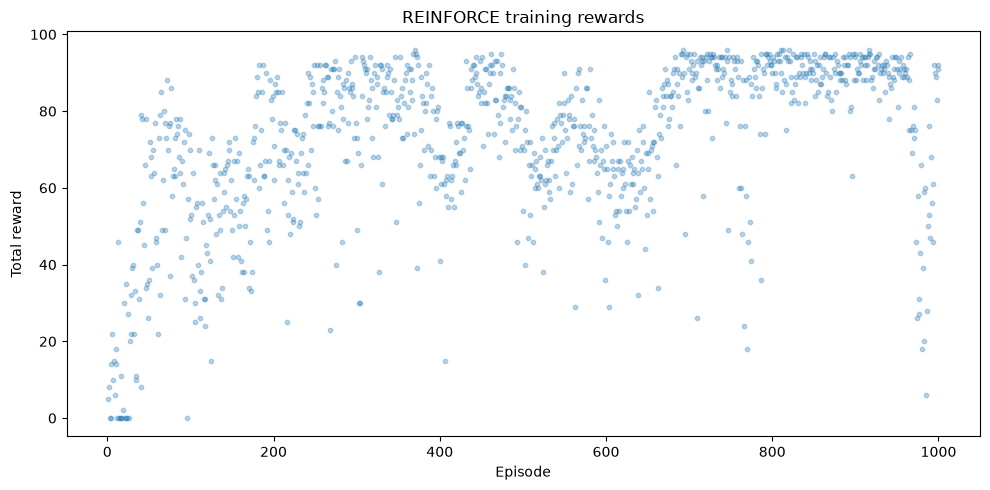

In [9]:
plt.figure(figsize=(10, 5))
plt.scatter(range(1, len(episode_rewards) + 1), episode_rewards, s=10, alpha=0.3)
plt.xlabel("Episode")
plt.ylabel("Total reward")
plt.title("REINFORCE training rewards")
plt.tight_layout()
plt.show()

### Save the weights for your policy.

Save your model weights from `pi` as `policy.pt` to be submitted in Gradescope.

In [10]:
torch.save(pi.state_dict(), "policy.pt")

## Gradescope Submission

Submit both your Jupyter notebook and `policy.pt` in Gradescope.

Make sure to check the Gradescope autograder results after submission.
**You will not receive credit for missing or misnamed files.**